In [1]:
# ============================================================
# CELL 1 — Setup and Configuration
# ============================================================

from pathlib import Path
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import networkx as nx
from torch.utils.data import Dataset, DataLoader
from torch_geometric.nn import GATv2Conv
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score
)

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEQ_LEN, BATCH_SIZE, EPOCHS = 24, 128, 35
LR, WEIGHT_DECAY = 1e-3, 1e-3

TARGETS = ["co", "no2", "o3", "pm10", "pm25", "so2"]

FEATURES = [
    "latitude", "longitude", "era5_t2m_c", "era5_d2m_c",
    "era5_sp_hpa", "era5_tp_mm", "era5_wind_speed",
    "era5_wind_dir", "era5_blh",
    "hour", "month", "dayofweek", "hour_sin",
    "hour_cos", "dow_sin", "dow_cos",
    "co_lag1", "co_lag24", "co_roll24_mean",
    "no2_lag1", "no2_lag24", "no2_roll24_mean",
    "o3_lag1", "o3_lag24", "o3_roll24_mean",
    "pm10_lag1", "pm10_lag24", "pm10_roll24_mean",
    "pm25_lag1", "pm25_lag24", "pm25_roll24_mean",
    "so2_lag1", "so2_lag24", "so2_roll24_mean"
]

assert (ROOT / "data/processed/train.csv").exists(), \
    f"Project root not found correctly: {ROOT}"

print("Root:", ROOT)
print("Device:", DEVICE)
print("Stations expected: 37")
print("Features:", len(FEATURES))
print("Targets:", len(TARGETS))
print("Sequence length:", SEQ_LEN)
print("Epochs:", EPOCHS)

C:\Users\vabhi\AppData\Roaming\Python\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\vabhi\AppData\Roaming\Python\Python311\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Root: c:\Users\vabhi\Downloads\Implementation\Implementation
Device: cpu
Stations expected: 37
Features: 34
Targets: 6
Sequence length: 24
Epochs: 35


In [2]:
# ============================================================
# CELL 2 — Load Data + Original Graph
# ============================================================

DATA_DIR = ROOT / "data/processed"
GRAPH_DIR = ROOT / "graph"
MODEL_DIR = ROOT / "models"
METRICS_DIR = ROOT / "metrics"

train = pd.read_csv(DATA_DIR / "train.csv", parse_dates=["datetime_utc"])
val = pd.read_csv(DATA_DIR / "val.csv", parse_dates=["datetime_utc"])
test = pd.read_csv(DATA_DIR / "test.csv", parse_dates=["datetime_utc"])

station_df = pd.read_csv(GRAPH_DIR / "station_metadata_final.csv")
edge_df = pd.read_csv(GRAPH_DIR / "edge_index_final.csv")

STATIONS = station_df.location_id.tolist()
N = len(STATIONS)
loc2idx = {s: i for i, s in enumerate(STATIONS)}

FULL_EDGE_INDEX = np.stack([
    edge_df.source.map(loc2idx).to_numpy(),
    edge_df.target.map(loc2idx).to_numpy()
])

G = nx.Graph()
G.add_nodes_from(STATIONS)
G.add_edges_from(edge_df[["source", "target"]].itertuples(index=False, name=None))

print("Stations:", N)
print("Original directed edges:", FULL_EDGE_INDEX.shape[1])
print("Original components:", nx.number_connected_components(G))
print(f"Train / Val / Test: {len(train):,} / {len(val):,} / {len(test):,}")

assert N == 37 and FULL_EDGE_INDEX.shape[1] == 169
assert len(FEATURES) == 34 and len(TARGETS) == 6

Stations: 37
Original directed edges: 169
Original components: 1
Train / Val / Test: 1,134,975 / 243,201 / 243,238


In [3]:
# ============================================================
# CELL 3 — Build Grids + Scaling
# ============================================================

def build_grid(df):
    times = pd.date_range(df.datetime_utc.min(), df.datetime_utc.max(), freq="h")
    tm = {t: i for i, t in enumerate(times)}
    sm = {s: i for i, s in enumerate(STATIONS)}

    X = np.full((len(times), N, len(FEATURES)), np.nan, np.float32)
    Y = np.full((len(times), N, 6), np.nan, np.float32)
    M = np.zeros_like(Y)

    d = df[df.location_id.isin(STATIONS)]
    ti = d.datetime_utc.map(tm).to_numpy()
    si = d.location_id.map(sm).to_numpy()
    X[ti, si] = d[FEATURES].to_numpy(np.float32)

    for k, target in enumerate(TARGETS):
        v = d[target].to_numpy(np.float32)
        ok = np.isfinite(v)
        Y[ti[ok], si[ok], k] = v[ok]
        M[ti[ok], si[ok], k] = 1

    return times, X, Y, M

train_time, train_X, train_Y, train_M = build_grid(train)
val_time, val_X, val_Y, val_M = build_grid(val)
test_time, test_X, test_Y, test_M = build_grid(test)

fill_values = np.nan_to_num(
    np.nanmedian(train_X.reshape(-1, len(FEATURES)), axis=0),
    nan=0.0
)

def fill(X):
    z = X.reshape(-1, len(FEATURES)).copy()
    r, c = np.where(~np.isfinite(z))
    z[r, c] = fill_values[c]
    return z.reshape(X.shape).astype(np.float32)

train_X, val_X, test_X = map(fill, [train_X, val_X, test_X])

feature_scaler = StandardScaler()
train_X = feature_scaler.fit_transform(train_X.reshape(-1, len(FEATURES))).reshape(train_X.shape).astype(np.float32)
val_X = feature_scaler.transform(val_X.reshape(-1, len(FEATURES))).reshape(val_X.shape).astype(np.float32)
test_X = feature_scaler.transform(test_X.reshape(-1, len(FEATURES))).reshape(test_X.shape).astype(np.float32)

target_mean = np.nanmean(train_Y.reshape(-1, 6), axis=0)
target_std = np.where(np.nanstd(train_Y.reshape(-1, 6), axis=0) > 0,
                      np.nanstd(train_Y.reshape(-1, 6), axis=0), 1)

def scale_y(Y):
    return ((Y - target_mean) / target_std).astype(np.float32)

def inv_y(Y):
    return Y * target_std + target_mean

train_Y, val_Y, test_Y = map(scale_y, [train_Y, val_Y, test_Y])

print("Training-only scaling complete.")
print("Train:", train_X.shape)
print("Val  :", val_X.shape)
print("Test :", test_X.shape)

Training-only scaling complete.
Train: (30675, 37, 34)
Val  : (6573, 37, 34)
Test : (6574, 37, 34)


In [4]:
# ============================================================
# CELL 4 — Pollutant History + Residual Targets
# ============================================================

def augment(X, Y, M):
    return np.concatenate([X, np.nan_to_num(Y, nan=0), M], axis=-1).astype(np.float32)

train_Xa, val_Xa, test_Xa = [
    augment(X, Y, M)
    for X, Y, M in [
        (train_X, train_Y, train_M),
        (val_X, val_Y, val_M),
        (test_X, test_Y, test_M)
    ]
]

raw_train, raw_val, raw_test = [inv_y(Y) for Y in [train_Y, val_Y, test_Y]]

def make_res(Y, M):
    R = np.full_like(Y, np.nan)
    R[1:] = Y[1:] - Y[:-1]
    RM = np.zeros_like(M)
    RM[1:] = M[1:] * M[:-1]
    return R, RM

train_R, train_RM = make_res(raw_train, train_M)
val_R, val_RM = make_res(raw_val, val_M)
test_R, test_RM = make_res(raw_test, test_M)

res_mean = np.nanmean(train_R.reshape(-1, 6), axis=0)
res_std = np.where(np.nanstd(train_R.reshape(-1, 6), axis=0) > 0,
                   np.nanstd(train_R.reshape(-1, 6), axis=0), 1)

def scale_r(R):
    return ((R - res_mean) / res_std).astype(np.float32)

train_R, val_R, test_R = map(scale_r, [train_R, val_R, test_R])

print("Input shape:", train_Xa.shape[-1])
print("Residual targets prepared.")
print("Train:", train_Xa.shape, train_R.shape, train_RM.shape)
print("Val  :", val_Xa.shape, val_R.shape, val_RM.shape)
print("Test :", test_Xa.shape, test_R.shape, test_RM.shape)

assert train_Xa.shape[-1] == 46

Input shape: 46
Residual targets prepared.
Train: (30675, 37, 46) (30675, 37, 6) (30675, 37, 6)
Val  : (6573, 37, 46) (6573, 37, 6) (6573, 37, 6)
Test : (6574, 37, 46) (6574, 37, 6) (6574, 37, 6)


In [5]:
# ============================================================
# CELL 5 — Sequence Dataloaders + Graph Ablation
# ============================================================

class RDataset(Dataset):
    def __init__(self, X, R, RM, Y):
        self.X, self.R, self.RM, self.Y = X, R, RM, Y
        self.t = np.arange(SEQ_LEN, len(X))

    def __len__(self):
        return len(self.t)

    def __getitem__(self, i):
        t = self.t[i]
        return self.X[t-SEQ_LEN:t], self.R[t], self.RM[t], self.Y[t-1]

# Ablation graph: each station connects only to itself.
ABL_EDGE_INDEX = np.stack([np.arange(N), np.arange(N)]).astype(np.int64)
ABL_EDGE_ATTR = np.zeros((N, 1), dtype=np.float32)

def collate(batch):
    X, R, RM, last = map(np.stack, zip(*batch))
    X, R, RM, last = [
        torch.tensor(a, dtype=torch.float32) for a in [X, R, RM, last]
    ]

    B, T, Nn, Fdim = X.shape
    off = np.arange(B) * Nn
    src = ABL_EDGE_INDEX[0][None, :] + off[:, None]
    dst = ABL_EDGE_INDEX[1][None, :] + off[:, None]
    ei = torch.tensor(np.vstack([src.ravel(), dst.ravel()]), dtype=torch.long)
    ea = torch.tensor(np.tile(ABL_EDGE_ATTR, (B, 1)), dtype=torch.float32)

    return {"x_grid": X, "edge_index": ei, "edge_attr": ea,
            "y": R, "mask": RM, "last": last}

train_loader = DataLoader(
    RDataset(train_Xa, train_R, train_RM, raw_train),
    batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate
)
val_loader = DataLoader(
    RDataset(val_Xa, val_R, val_RM, raw_val),
    batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate
)
test_loader = DataLoader(
    RDataset(test_Xa, test_R, test_RM, raw_test),
    batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate
)

print("Ablation edges per station:", ABL_EDGE_INDEX.shape[1] // N)
print("Cross-station edges:", 0)
print("Samples:", len(train_loader.dataset), "/", len(val_loader.dataset), "/", len(test_loader.dataset))
print("Batch edge index:", next(iter(val_loader))["edge_index"].shape)

Ablation edges per station: 1
Cross-station edges: 0
Samples: 30651 / 6549 / 6550
Batch edge index: torch.Size([2, 4736])


In [6]:
# ============================================================
# CELL 6 — Residual GAT-LSTM Without Cross-Station Edges
# ============================================================

class ResidualGATLSTM(nn.Module):
    def __init__(self, Fdim, hidden=128, heads=4, drop=0.2):
        super().__init__()
        self.lstm = nn.LSTM(Fdim, hidden, 2, batch_first=True, dropout=drop)
        self.emb = nn.Embedding(N, 16)
        self.gat1 = GATv2Conv(hidden + 16, hidden // heads, heads=heads, edge_dim=1)
        self.gat2 = GATv2Conv(hidden, hidden, edge_dim=1)
        self.n1 = nn.LayerNorm(hidden)
        self.n2 = nn.LayerNorm(hidden)
        self.drop = nn.Dropout(drop)
        self.heads = nn.ModuleList([
            nn.Sequential(
                nn.Linear(hidden, 64), nn.SiLU(),
                nn.Dropout(drop), nn.Linear(64, 1)
            )
            for _ in TARGETS
        ])

    def forward(self, b):
        X = b["x_grid"]
        B, T, Nn, Fdim = X.shape

        x = X.permute(0, 2, 1, 3).reshape(B * Nn, T, Fdim)
        h, _ = self.lstm(x)
        h = h[:, -1].view(B, Nn, -1)

        e = self.emb(torch.arange(N, device=h.device)).unsqueeze(0).expand(B, -1, -1)
        h = torch.cat([h, e], -1).reshape(B * Nn, -1)

        ei = b["edge_index"].to(h.device)
        ea = b["edge_attr"].to(h.device)

        z = F.elu(self.gat1(h, ei, edge_attr=ea))
        z = self.drop(self.n1(z))
        z = self.gat2(z, ei, edge_attr=ea)
        z = self.n2(z + h[:, :z.shape[1]])
        z = self.drop(z).view(B, Nn, -1)

        return torch.cat([head(z) for head in self.heads], -1)

model = ResidualGATLSTM(46).to(DEVICE)

print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Device:", DEVICE)
print("Graph mode: self-connections only")
assert sum(p.numel() for p in model.parameters()) == 344150

Parameters: 344,150
Device: cpu
Graph mode: self-connections only


In [7]:
# ============================================================
# CELL 7 — Ablation Model Smoke Test
# ============================================================

model.eval()
batch = next(iter(val_loader))
batch = {k: v.to(DEVICE) for k, v in batch.items()}

with torch.no_grad():
    pred = model(batch)

mask = batch["mask"].bool()
loss = F.smooth_l1_loss(pred[mask], batch["y"][mask])

print("Input:", tuple(batch["x_grid"].shape))
print("Edge index:", tuple(batch["edge_index"].shape))
print("Edge attributes:", tuple(batch["edge_attr"].shape))
print("Prediction:", tuple(pred.shape))
print("Masked loss:", round(loss.item(), 6))
print("Finite predictions:", bool(torch.isfinite(pred).all()))

assert pred.shape == (batch["x_grid"].shape[0], 37, 6)
assert torch.isfinite(pred).all()
assert torch.isfinite(loss)

Input: (128, 24, 37, 46)
Edge index: (2, 4736)
Edge attributes: (4736, 1)
Prediction: (128, 37, 6)
Masked loss: 0.126318
Finite predictions: True


In [8]:
# ============================================================
# CELL 8 — Train or Reuse the No-Cross-Station Graph Ablation
# ============================================================

CHECKPOINT = MODEL_DIR / "gat_lstm_no_cross_station.pt"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

# Keep False to reuse the checkpoint from the completed spatial ablation.
# Set True only when you intentionally want to retrain it.
RETRAIN_GRAPH_ABLATION = False

def loss_fn(pred, target, mask):
    valid = mask.bool()
    return F.smooth_l1_loss(pred[valid], target[valid]) if valid.any() else None

if CHECKPOINT.exists() and not RETRAIN_GRAPH_ABLATION:
    model.load_state_dict(torch.load(CHECKPOINT, map_location=DEVICE))
    model.eval()
    print("Reused existing graph-ablation checkpoint:", CHECKPOINT)
    history_path = METRICS_DIR / "gat_lstm_graph_ablation_training.csv"
    if history_path.exists():
        history_df = pd.read_csv(history_path)
        if "val_loss" in history_df:
            best_val = float(history_df["val_loss"].min())
            print("Recorded best validation loss:", round(best_val, 6))
    print("Set RETRAIN_GRAPH_ABLATION=True to train this ablation again.")
else:
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY,
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, EPOCHS
    )

    best_val = np.inf
    history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_loss = batches = 0

        for batch in train_loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            optimizer.zero_grad()

            pred = model(batch)
            loss = loss_fn(pred, batch["y"], batch["mask"])

            if loss is None or not torch.isfinite(loss):
                continue

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            train_loss += loss.item()
            batches += 1

        model.eval()
        val_loss = val_batches = 0

        with torch.no_grad():
            for batch in val_loader:
                batch = {k: v.to(DEVICE) for k, v in batch.items()}
                loss = loss_fn(model(batch), batch["y"], batch["mask"])

                if loss is None or not torch.isfinite(loss):
                    continue

                val_loss += loss.item()
                val_batches += 1

        train_loss /= max(batches, 1)
        val_loss /= max(val_batches, 1)
        scheduler.step()

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
        })

        if val_loss < best_val:
            best_val = val_loss
            torch.save(model.state_dict(), CHECKPOINT)

        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"Train={train_loss:.5f} | Val={val_loss:.5f}"
        )

    model.load_state_dict(torch.load(CHECKPOINT, map_location=DEVICE))
    model.eval()

    history_df = pd.DataFrame(history)
    history_path = METRICS_DIR / "gat_lstm_graph_ablation_training.csv"
    history_df.to_csv(history_path, index=False)

    print("\nBest validation loss:", round(best_val, 6))
    print("Checkpoint:", CHECKPOINT)
    print("Training history saved:", history_path)

Reused existing graph-ablation checkpoint: c:\Users\vabhi\Downloads\Implementation\Implementation\models\gat_lstm_no_cross_station.pt
Recorded best validation loss: 0.174131
Set RETRAIN_GRAPH_ABLATION=True to train this ablation again.


In [9]:
# ============================================================
# CELL 9 — Evaluate No-Cross-Station Model on the Test Set
# ============================================================

model.eval()
predictions, masks, last_values = [], [], []

with torch.no_grad():
    for batch in test_loader:
        bt = {k: v.to(DEVICE) for k, v in batch.items()}
        predictions.append(model(bt).cpu().numpy())
        masks.append(batch["mask"].numpy())
        last_values.append(batch["last"].numpy())

P = np.concatenate(predictions)
M = np.concatenate(masks).astype(bool)
L = np.nan_to_num(np.concatenate(last_values), nan=0.0)

# Convert normalized residual predictions back to pollutant concentrations.
P = P * res_std + res_mean + L
Y = raw_test[SEQ_LEN:]

assert P.shape == Y.shape == M.shape
assert P.shape[1:] == (N, len(TARGETS))
assert np.isfinite(P).all()

reg_rows = []
for k, pollutant in enumerate(TARGETS):
    valid = M[:, :, k] & np.isfinite(Y[:, :, k])
    yt, yp = Y[:, :, k][valid], P[:, :, k][valid]

    reg_rows.append({
        "Model": "No cross-station edges",
        "Pollutant": pollutant,
        "MAE": mean_absolute_error(yt, yp),
        "RMSE": np.sqrt(mean_squared_error(yt, yp)),
        "R2": r2_score(yt, yp),
        "Valid samples": int(valid.sum()),
    })

reg_ablation = pd.DataFrame(reg_rows)
reg_ablation.to_csv(
    METRICS_DIR / "gat_lstm_graph_ablation_test_metrics.csv",
    index=False,
)

np.save(MODEL_DIR / "gat_lstm_graph_ablation_test_predictions.npy", P)
np.save(MODEL_DIR / "gat_lstm_graph_ablation_test_targets.npy", Y)
np.save(MODEL_DIR / "gat_lstm_graph_ablation_test_mask.npy", M)

print("GRAPH ABLATION — TEST REGRESSION")
print(reg_ablation.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print("\nSaved graph-ablation predictions, targets, masks, and metrics.")

GRAPH ABLATION — TEST REGRESSION
                 Model Pollutant       MAE      RMSE       R2  Valid samples
No cross-station edges        co  0.156790  0.342604 0.873409         188999
No cross-station edges       no2  5.035731  9.297083 0.922921         190746
No cross-station edges        o3  5.280289 11.145946 0.917086         189143
No cross-station edges      pm10 23.088758 42.487365 0.915971         187845
No cross-station edges      pm25 12.123948 24.859657 0.934429         187322
No cross-station edges       so2  2.261621  5.553043 0.826529         166867

Saved graph-ablation predictions, targets, masks, and metrics.


In [10]:
# ============================================================
# CELL 10 — Load and Verify Full-Model Test Predictions
# ============================================================

full_P = np.load(MODEL_DIR / "gat_lstm_test_predictions.npy")
full_Y = np.load(MODEL_DIR / "gat_lstm_test_targets.npy")
full_M = np.load(MODEL_DIR / "gat_lstm_test_mask.npy").astype(bool)

print("Full predictions:", full_P.shape)
print("Full targets:", full_Y.shape)
print("Full mask:", full_M.shape)

assert full_P.shape == P.shape
assert full_Y.shape == Y.shape
assert full_M.shape == M.shape
assert np.array_equal(full_M, M), "Full and graph-ablation test masks differ."
assert np.allclose(full_Y, Y, equal_nan=True), "Full and graph-ablation targets differ."
assert np.isfinite(full_P).all()

print("✓ Full-model and graph-ablation test arrays are aligned.")

Full predictions: (6550, 37, 6)
Full targets: (6550, 37, 6)
Full mask: (6550, 37, 6)
✓ Full-model and graph-ablation test arrays are aligned.


## AQI calculation protocol used for the ablation comparison

The attached CPCB National AQI sheet specifies 24-hour averages for PM10, PM2.5, NO2 and SO2, and 8-hour values for CO and O3. Therefore, the comparison below calculates trailing rolling averages of the hourly test predictions and observed concentrations before applying the AQI breakpoints.

To keep the three models directly comparable, an AQI sample is retained only when all six observed pollutant averages have complete windows. This is a conservative research-evaluation rule for a common sample set; it is not a claim that CPCB's operational AQI reporting rules require 100% completeness for every pollutant.

The open-ended “Severe” concentration bands do not provide an upper concentration breakpoint in the attached table. In this implementation they are capped at AQI 500 for category assignment.

In [11]:
# ============================================================
# CELL 11 — CPCB Breakpoints + Period-Averaging Helpers
# ============================================================

AQI_CATS = [
    "Good", "Satisfactory", "Moderately polluted",
    "Poor", "Very Poor", "Severe"
]

# Concentration breakpoints follow the attached CPCB table.
# Internal interpolation anchors use the previous category's upper
# concentration/AQI endpoint so that a shared endpoint is not overwritten.
AQI_BP = {
    "pm10": [
        (0, 50, 0, 50), (50, 100, 50, 100), (100, 250, 100, 200),
        (250, 350, 200, 300), (350, 430, 300, 400), (430, np.inf, 400, 500)
    ],
    "pm25": [
        (0, 30, 0, 50), (30, 60, 50, 100), (60, 90, 100, 200),
        (90, 120, 200, 300), (120, 250, 300, 400), (250, np.inf, 400, 500)
    ],
    "no2": [
        (0, 40, 0, 50), (40, 80, 50, 100), (80, 180, 100, 200),
        (180, 280, 200, 300), (280, 400, 300, 400), (400, np.inf, 400, 500)
    ],
    "o3": [
        (0, 50, 0, 50), (50, 100, 50, 100), (100, 168, 100, 200),
        (168, 208, 200, 300), (208, 748, 300, 400), (748, np.inf, 400, 500)
    ],
    "co": [
        (0, 1, 0, 50), (1, 2, 50, 100), (2, 10, 100, 200),
        (10, 17, 200, 300), (17, 34, 300, 400), (34, np.inf, 400, 500)
    ],
    "so2": [
        (0, 40, 0, 50), (40, 80, 50, 100), (80, 380, 100, 200),
        (380, 800, 200, 300), (800, 1600, 300, 400), (1600, np.inf, 400, 500)
    ],
}

# CPCB averaging windows (hours) from the footnote in the attached sheet.
AQI_WINDOW_HOURS = {
    "co": 8,
    "no2": 24,
    "o3": 8,
    "pm10": 24,
    "pm25": 24,
    "so2": 24,
}

def subindex(values, pollutant):
    """
    Convert concentrations to CPCB-breakpoint-based pollutant sub-indices.
    Each shared upper endpoint belongs to the lower interval, preventing
    the previous implementation from overwriting values such as PM2.5=30.
    The open-ended Severe band is capped at 500 because no upper
    concentration breakpoint is supplied in the attached table.
    """
    values = np.asarray(values, dtype=float)
    out = np.full(values.shape, np.nan, dtype=float)
    valid_values = np.isfinite(values) & (values >= 0)

    for i, (lo, hi, ilo, ihi) in enumerate(AQI_BP[pollutant]):
        if i == 0:
            in_band = (values >= lo) & (values <= hi)
        elif np.isfinite(hi):
            in_band = (values > lo) & (values <= hi)
        else:
            in_band = values > lo

        use = valid_values & in_band & np.isnan(out)
        if not np.any(use):
            continue

        if np.isinf(hi):
            out[use] = 500.0
        else:
            out[use] = ilo + (ihi - ilo) * (values[use] - lo) / (hi - lo)

    # The CPCB sheet's worked PM2.5 example reports integer sub-indices
    # (31 -> 51; 45 -> 75; 60 -> 100).
    return np.floor(out)

# Sanity checks against the worked PM2.5 example in the supplied CPCB sheet.
assert subindex([30], "pm25")[0] == 50
assert subindex([31], "pm25")[0] == 51
assert subindex([45], "pm25")[0] == 75
assert subindex([60], "pm25")[0] == 100

def rolling_mean_complete(values, valid_mask, window):
    """
    Trailing mean across time for each station.
    A window is usable only when every hourly observation in that window
    is valid. Returns (means, window_validity_mask).
    Input arrays must have shape (time, station).
    """
    values = np.asarray(values, dtype=float)
    valid_mask = np.asarray(valid_mask, dtype=bool)
    if values.ndim != 2 or valid_mask.shape != values.shape:
        raise ValueError("values and valid_mask must both have shape (time, station).")
    if window < 1 or window > len(values):
        raise ValueError(f"Invalid rolling window: {window}")

    means = np.full(values.shape, np.nan, dtype=float)
    out_mask = np.zeros(values.shape, dtype=bool)

    for t in range(window - 1, len(values)):
        block = values[t - window + 1:t + 1]
        block_mask = valid_mask[t - window + 1:t + 1] & np.isfinite(block)
        station_ok = block_mask.all(axis=0)
        if station_ok.any():
            means[t, station_ok] = block[:, station_ok].mean(axis=0)
            out_mask[t, station_ok] = True

    return means, out_mask

def aqi_classes_from_concentrations(concentrations, valid_mask):
    """
    Return overall AQI category for valid (time, station) positions.
    concentrations has shape (time, station, 6).
    """
    values = np.clip(np.asarray(concentrations[valid_mask], dtype=float), 0, None)
    if values.ndim != 2 or values.shape[1] != len(TARGETS):
        raise ValueError("Expected a 6-column concentration array after masking.")

    indices = np.column_stack([
        subindex(values[:, k], pollutant)
        for k, pollutant in enumerate(TARGETS)
    ])
    overall_aqi = np.nanmax(indices, axis=1)

    return pd.cut(
        overall_aqi,
        [-np.inf, 50, 100, 200, 300, 400, np.inf],
        labels=AQI_CATS,
        include_lowest=True,
    )

print("AQI breakpoints loaded for:", ", ".join(TARGETS))
print("Averaging windows:", AQI_WINDOW_HOURS)
print("✓ Shared-endpoint tests passed.")

AQI breakpoints loaded for: co, no2, o3, pm10, pm25, so2
Averaging windows: {'co': 8, 'no2': 24, 'o3': 8, 'pm10': 24, 'pm25': 24, 'so2': 24}
✓ Shared-endpoint tests passed.


In [12]:
# ============================================================
# CELL 12 — Full-Graph Loaders for the Temporal Ablation
# ============================================================

# Use the exact 169-edge graph and raw distance attributes from the full model.
FULL_EDGE_ATTR = edge_df["distance_km"].to_numpy(dtype=np.float32).reshape(-1, 1)

assert FULL_EDGE_INDEX.shape == (2, 169)
assert FULL_EDGE_ATTR.shape == (169, 1)
assert np.isfinite(FULL_EDGE_ATTR).all()

def make_graph_collate(edge_index_np, edge_attr_np):
    edge_index_np = np.asarray(edge_index_np, dtype=np.int64)
    edge_attr_np = np.asarray(edge_attr_np, dtype=np.float32)

    if edge_index_np.shape[0] != 2:
        raise ValueError("edge_index must have shape (2, number_of_edges).")
    if edge_attr_np.shape != (edge_index_np.shape[1], 1):
        raise ValueError("edge_attr must have shape (number_of_edges, 1).")

    def _collate(batch):
        X, R, RM, last = map(np.stack, zip(*batch))
        X, R, RM, last = [
            torch.tensor(a, dtype=torch.float32)
            for a in (X, R, RM, last)
        ]

        B, T, Nn, Fdim = X.shape
        offsets = np.arange(B, dtype=np.int64) * Nn
        src = edge_index_np[0][None, :] + offsets[:, None]
        dst = edge_index_np[1][None, :] + offsets[:, None]

        ei = torch.tensor(
            np.vstack([src.ravel(), dst.ravel()]),
            dtype=torch.long,
        )
        ea = torch.tensor(
            np.tile(edge_attr_np, (B, 1)),
            dtype=torch.float32,
        )

        return {
            "x_grid": X,
            "edge_index": ei,
            "edge_attr": ea,
            "y": R,
            "mask": RM,
            "last": last,
        }

    return _collate

full_graph_collate = make_graph_collate(FULL_EDGE_INDEX, FULL_EDGE_ATTR)
train_generator = torch.Generator()
train_generator.manual_seed(SEED)

temporal_train_loader = DataLoader(
    RDataset(train_Xa, train_R, train_RM, raw_train),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=full_graph_collate,
    generator=train_generator,
)
temporal_val_loader = DataLoader(
    RDataset(val_Xa, val_R, val_RM, raw_val),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=full_graph_collate,
)
temporal_test_loader = DataLoader(
    RDataset(test_Xa, test_R, test_RM, raw_test),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=full_graph_collate,
)

print("Full graph edges:", FULL_EDGE_INDEX.shape[1])
print("Distance edge attributes:", FULL_EDGE_ATTR.shape)
print(
    "Temporal-ablation samples:",
    len(temporal_train_loader.dataset),
    "/",
    len(temporal_val_loader.dataset),
    "/",
    len(temporal_test_loader.dataset),
)

Full graph edges: 169
Distance edge attributes: (169, 1)
Temporal-ablation samples: 30651 / 6549 / 6550


In [13]:
# ============================================================
# CELL 13 — GAT Model Without the LSTM Sequence Encoder
# ============================================================

class ResidualGATLastStep(nn.Module):
    """
    Temporal ablation:
    - Uses only the latest timestep's 46-dimensional input vector.
    - Replaces the LSTM with a Linear -> SiLU projection to 128 dimensions.
    - Retains station embeddings, both GATv2 layers, residual connection,
      normalization, dropout, edge-distance attributes, and pollutant heads.
    """
    def __init__(self, Fdim, hidden=128, heads=4, drop=0.2):
        super().__init__()
        self.latest_encoder = nn.Sequential(
            nn.Linear(Fdim, hidden),
            nn.SiLU(),
            nn.Dropout(drop),
        )
        self.emb = nn.Embedding(N, 16)
        self.gat1 = GATv2Conv(
            hidden + 16, hidden // heads, heads=heads, edge_dim=1
        )
        self.gat2 = GATv2Conv(hidden, hidden, edge_dim=1)
        self.n1 = nn.LayerNorm(hidden)
        self.n2 = nn.LayerNorm(hidden)
        self.drop = nn.Dropout(drop)
        self.heads = nn.ModuleList([
            nn.Sequential(
                nn.Linear(hidden, 64),
                nn.SiLU(),
                nn.Dropout(drop),
                nn.Linear(64, 1),
            )
            for _ in TARGETS
        ])

    def forward(self, b):
        X = b["x_grid"]
        B, T, Nn, Fdim = X.shape

        # Deliberately discard earlier timesteps for this ablation.
        h_latest = self.latest_encoder(X[:, -1, :, :])
        residual = h_latest.reshape(B * Nn, -1)

        station_ids = torch.arange(N, device=X.device)
        e = self.emb(station_ids).unsqueeze(0).expand(B, -1, -1)
        h = torch.cat([h_latest, e], dim=-1).reshape(B * Nn, -1)

        ei = b["edge_index"].to(h.device)
        ea = b["edge_attr"].to(h.device)

        z = F.elu(self.gat1(h, ei, edge_attr=ea))
        z = self.drop(self.n1(z))
        z = self.gat2(z, ei, edge_attr=ea)
        z = self.n2(z + residual)
        z = self.drop(z).view(B, Nn, -1)

        return torch.cat([head(z) for head in self.heads], dim=-1)

# Reset seed so this experiment is repeatable independently of prior cells.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

temporal_model = ResidualGATLastStep(len(FEATURES) + 12).to(DEVICE)

print("Temporal ablation parameters:", f"{sum(p.numel() for p in temporal_model.parameters()):,}")
print("Device:", DEVICE)
print("Temporal input used: latest timestep only")
print("Spatial graph: all 169 directed edges with distance attributes")

Temporal ablation parameters: 127,958
Device: cpu
Temporal input used: latest timestep only
Spatial graph: all 169 directed edges with distance attributes


In [14]:
# ============================================================
# CELL 14 — Temporal Ablation Smoke Test
# ============================================================

temporal_model.eval()
batch = next(iter(temporal_val_loader))
batch = {k: v.to(DEVICE) for k, v in batch.items()}

with torch.no_grad():
    pred_smoke = temporal_model(batch)

mask_smoke = batch["mask"].bool()
loss_smoke = F.smooth_l1_loss(
    pred_smoke[mask_smoke],
    batch["y"][mask_smoke],
)

print("Input sequence:", tuple(batch["x_grid"].shape))
print("Full-graph edge index:", tuple(batch["edge_index"].shape))
print("Edge attributes:", tuple(batch["edge_attr"].shape))
print("Prediction:", tuple(pred_smoke.shape))
print("Masked loss:", round(loss_smoke.item(), 6))
print("Finite predictions:", bool(torch.isfinite(pred_smoke).all()))

assert pred_smoke.shape == (batch["x_grid"].shape[0], N, len(TARGETS))
assert torch.isfinite(pred_smoke).all()
assert torch.isfinite(loss_smoke)

Input sequence: (128, 24, 37, 46)
Full-graph edge index: (2, 21632)
Edge attributes: (21632, 1)
Prediction: (128, 37, 6)
Masked loss: 0.128347
Finite predictions: True


In [15]:

# ============================================================
# CELL 15 — Train or Reuse the No-LSTM Temporal Ablation
# ============================================================

TEMP_CHECKPOINT = (
    MODEL_DIR / "gat_lstm_temporal_ablation_latest_step.pt"
)

TEMP_HISTORY_PATH = (
    METRICS_DIR / "gat_lstm_temporal_ablation_training.csv"
)

MODEL_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

# Keep False to reuse the previously trained temporal ablation.
RETRAIN_TEMPORAL_ABLATION = False

if TEMP_CHECKPOINT.exists() and not RETRAIN_TEMPORAL_ABLATION:

    temporal_model.load_state_dict(
        torch.load(TEMP_CHECKPOINT, map_location=DEVICE)
    )
    temporal_model.eval()

    print("Reused temporal-ablation checkpoint:", TEMP_CHECKPOINT)

    if TEMP_HISTORY_PATH.exists():
        temporal_history_df = pd.read_csv(TEMP_HISTORY_PATH)

        if "val_loss" in temporal_history_df.columns:
            print(
                "Recorded best validation loss:",
                f"{temporal_history_df['val_loss'].min():.6f}",
            )
    else:
        print("No saved temporal-ablation training history found.")

    print("Training skipped.")

else:

    temporal_optimizer = torch.optim.AdamW(
        temporal_model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY,
    )

    temporal_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        temporal_optimizer,
        EPOCHS,
    )

    best_temporal_val = np.inf
    temporal_history = []

    for epoch in range(1, EPOCHS + 1):

        temporal_model.train()
        epoch_train_loss = 0.0
        train_batches = 0

        for batch in temporal_train_loader:

            batch = {
                k: v.to(DEVICE)
                for k, v in batch.items()
            }

            temporal_optimizer.zero_grad()

            pred_batch = temporal_model(batch)
            loss = loss_fn(
                pred_batch,
                batch["y"],
                batch["mask"],
            )

            if loss is None or not torch.isfinite(loss):
                continue

            loss.backward()

            nn.utils.clip_grad_norm_(
                temporal_model.parameters(),
                1.0,
            )

            temporal_optimizer.step()

            epoch_train_loss += loss.item()
            train_batches += 1

        temporal_model.eval()
        epoch_val_loss = 0.0
        val_batches = 0

        with torch.no_grad():

            for batch in temporal_val_loader:

                batch = {
                    k: v.to(DEVICE)
                    for k, v in batch.items()
                }

                loss = loss_fn(
                    temporal_model(batch),
                    batch["y"],
                    batch["mask"],
                )

                if loss is None or not torch.isfinite(loss):
                    continue

                epoch_val_loss += loss.item()
                val_batches += 1

        epoch_train_loss /= max(train_batches, 1)
        epoch_val_loss /= max(val_batches, 1)

        temporal_scheduler.step()

        temporal_history.append({
            "epoch": epoch,
            "train_loss": epoch_train_loss,
            "val_loss": epoch_val_loss,
        })

        if epoch_val_loss < best_temporal_val:

            best_temporal_val = epoch_val_loss

            torch.save(
                temporal_model.state_dict(),
                TEMP_CHECKPOINT,
            )

        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"Train={epoch_train_loss:.5f} | "
            f"Val={epoch_val_loss:.5f}"
        )

    temporal_model.load_state_dict(
        torch.load(TEMP_CHECKPOINT, map_location=DEVICE)
    )
    temporal_model.eval()

    temporal_history_df = pd.DataFrame(temporal_history)
    temporal_history_df.to_csv(
        TEMP_HISTORY_PATH,
        index=False,
    )

    print("\nBest validation loss:", f"{best_temporal_val:.6f}")
    print("Checkpoint:", TEMP_CHECKPOINT)
    print("Training history:", TEMP_HISTORY_PATH)


Reused temporal-ablation checkpoint: c:\Users\vabhi\Downloads\Implementation\Implementation\models\gat_lstm_temporal_ablation_latest_step.pt
Recorded best validation loss: 0.173441
Training skipped.


In [16]:
# ============================================================
# CELL 16 — Evaluate the No-LSTM Temporal Ablation
# ============================================================

temporal_model.eval()
temporal_predictions, temporal_masks, temporal_last_values = [], [], []

with torch.no_grad():
    for batch in temporal_test_loader:
        bt = {k: v.to(DEVICE) for k, v in batch.items()}
        temporal_predictions.append(temporal_model(bt).cpu().numpy())
        temporal_masks.append(batch["mask"].numpy())
        temporal_last_values.append(batch["last"].numpy())

P_temporal = np.concatenate(temporal_predictions)
M_temporal = np.concatenate(temporal_masks).astype(bool)
L_temporal = np.nan_to_num(
    np.concatenate(temporal_last_values),
    nan=0.0,
)

# Undo residual scaling and reconstruct pollutant concentrations.
P_temporal = P_temporal * res_std + res_mean + L_temporal
Y_temporal = raw_test[SEQ_LEN:]

assert P_temporal.shape == Y_temporal.shape == M_temporal.shape
assert P_temporal.shape == full_P.shape
assert np.isfinite(P_temporal).all()
assert np.array_equal(M_temporal, full_M)
assert np.allclose(Y_temporal, full_Y, equal_nan=True)

temporal_reg_rows = []
for k, pollutant in enumerate(TARGETS):
    valid = M_temporal[:, :, k] & np.isfinite(Y_temporal[:, :, k])
    yt = Y_temporal[:, :, k][valid]
    yp = P_temporal[:, :, k][valid]
    temporal_reg_rows.append({
        "Model": "No LSTM (latest timestep)",
        "Pollutant": pollutant,
        "MAE": mean_absolute_error(yt, yp),
        "RMSE": np.sqrt(mean_squared_error(yt, yp)),
        "R2": r2_score(yt, yp),
        "Valid samples": int(valid.sum()),
    })

temporal_reg = pd.DataFrame(temporal_reg_rows)
temporal_reg.to_csv(
    METRICS_DIR / "gat_lstm_temporal_ablation_test_metrics.csv",
    index=False,
)
np.save(MODEL_DIR / "gat_lstm_temporal_ablation_test_predictions.npy", P_temporal)
np.save(MODEL_DIR / "gat_lstm_temporal_ablation_test_targets.npy", Y_temporal)
np.save(MODEL_DIR / "gat_lstm_temporal_ablation_test_mask.npy", M_temporal)

print("TEMPORAL ABLATION — TEST REGRESSION")
print(temporal_reg.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print("\nSaved temporal-ablation predictions, targets, masks, and metrics.")

TEMPORAL ABLATION — TEST REGRESSION
                    Model Pollutant       MAE      RMSE       R2  Valid samples
No LSTM (latest timestep)        co  0.156323  0.339105 0.875981         188999
No LSTM (latest timestep)       no2  5.088172  9.340070 0.922207         190746
No LSTM (latest timestep)        o3  5.396235 11.215438 0.916049         189143
No LSTM (latest timestep)      pm10 22.819771 42.169475 0.917224         187845
No LSTM (latest timestep)      pm25 11.909254 24.216048 0.937780         187322
No LSTM (latest timestep)       so2  2.227144  5.398388 0.836057         166867

Saved temporal-ablation predictions, targets, masks, and metrics.


In [18]:

# ============================================================
# CELL 17 — Final Three-Model Regression + AQI Comparison
# ============================================================

MODEL_PREDICTIONS = {
    "Full GAT-LSTM": full_P,
    "No cross-station edges": P,
    "No LSTM (latest timestep)": P_temporal,
}

MODEL_MASKS = {
    "Full GAT-LSTM": full_M,
    "No cross-station edges": M,
    "No LSTM (latest timestep)": M_temporal,
}

model_order = [
    "Full GAT-LSTM",
    "No cross-station edges",
    "No LSTM (latest timestep)",
]

MODEL_SLUG = {
    "Full GAT-LSTM": "gat_lstm",
    "No cross-station edges": "no_cross_station",
    "No LSTM (latest timestep)": "no_lstm",
}

pollutant_labels = {
    "co": "CO",
    "no2": "NO2",
    "o3": "O3",
    "pm10": "PM10",
    "pm25": "PM2.5",
    "so2": "SO2",
}

METRICS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Verify shared regression targets, masks, and predictions
# ------------------------------------------------------------

for model_name in model_order:

    pred_array = MODEL_PREDICTIONS[model_name]
    mask_array = MODEL_MASKS[model_name]

    if pred_array.shape != full_P.shape:
        raise ValueError(
            f"{model_name}: prediction shape {pred_array.shape} "
            f"does not match full model {full_P.shape}."
        )

    if mask_array.shape != full_M.shape:
        raise ValueError(
            f"{model_name}: prediction mask shape mismatch."
        )

    if not np.array_equal(mask_array, full_M):
        raise ValueError(
            f"{model_name}: evaluation mask differs from the full model."
        )

    if not np.isfinite(pred_array).all():
        raise ValueError(
            f"{model_name}: predictions contain non-finite values."
        )

if not np.allclose(full_Y, Y, equal_nan=True):
    raise ValueError("Graph-ablation targets differ from full-model targets.")

if not np.allclose(full_Y, Y_temporal, equal_nan=True):
    raise ValueError("Temporal-ablation targets differ from full-model targets.")

actual_test = full_Y

# ------------------------------------------------------------
# 2. Regression metrics on the same valid rows per pollutant
# ------------------------------------------------------------

regression_rows = []

for k, pollutant in enumerate(TARGETS):

    valid = (
        full_M[:, :, k]
        & np.isfinite(actual_test[:, :, k])
    )

    # Require finite predictions from all three models on each
    # pollutant-specific cohort.
    for model_name in model_order:
        valid &= np.isfinite(
            MODEL_PREDICTIONS[model_name][:, :, k]
        )

    y_true = actual_test[:, :, k][valid]

    if len(y_true) == 0:
        raise ValueError(
            f"No common valid regression observations for {pollutant}."
        )

    for model_name in model_order:

        y_pred = MODEL_PREDICTIONS[model_name][:, :, k][valid]

        regression_rows.append({
            "Pollutant": pollutant_labels[pollutant],
            "Pollutant code": pollutant,
            "Model": model_name,
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred),
            "Valid test samples": int(len(y_true)),
        })

regression_comparison_long = pd.DataFrame(regression_rows)

regression_comparison_long.to_csv(
    METRICS_DIR / "gat_lstm_three_model_regression_long.csv",
    index=False,
)

wide = regression_comparison_long.pivot(
    index=["Pollutant", "Pollutant code"],
    columns="Model",
    values=["MAE", "RMSE", "R2"],
)

wide.columns = [
    f"{metric}_{model_name}"
    for metric, model_name in wide.columns
]

wide = wide.reset_index()

final_regression_table = wide[
    ["Pollutant", "Pollutant code"]
    + [
        f"{metric}_{model_name}"
        for metric in ["MAE", "RMSE", "R2"]
        for model_name in model_order
    ]
].copy()

for model_name, short_name in [
    ("No cross-station edges", "NoSpatial"),
    ("No LSTM (latest timestep)", "NoLSTM"),
]:

    final_regression_table[f"{short_name}_MAE_change_%"] = (
        (
            final_regression_table[f"MAE_{model_name}"]
            / final_regression_table["MAE_Full GAT-LSTM"]
        ) - 1
    ) * 100

    final_regression_table[f"{short_name}_R2_change"] = (
        final_regression_table[f"R2_{model_name}"]
        - final_regression_table["R2_Full GAT-LSTM"]
    )

final_regression_table.to_csv(
    METRICS_DIR / "gat_lstm_three_model_regression_wide.csv",
    index=False,
)

# ------------------------------------------------------------
# 3. Compute actual hourly rolling means from the original test CSV
# ------------------------------------------------------------

source_times = pd.DatetimeIndex(
    pd.to_datetime(test_time, utc=True).tz_localize(None)
)

output_times = source_times[SEQ_LEN:]

if len(output_times) != full_P.shape[0]:
    raise ValueError(
        f"Test timestamps {len(output_times)} do not align with "
        f"prediction time dimension {full_P.shape[0]}."
    )

q_actual = test[
    ["datetime_utc", "location_id"] + TARGETS
].copy()

q_actual["time_key"] = (
    pd.to_datetime(q_actual["datetime_utc"], utc=True)
    .dt.tz_localize(None)
)

q_actual["loc_key"] = q_actual["location_id"].astype(str)

q_actual = q_actual.sort_values(
    ["loc_key", "time_key"]
).reset_index(drop=True)

if q_actual.duplicated(["loc_key", "time_key"]).any():
    raise ValueError("Duplicate timestamp/station rows in test.csv.")

time_to_idx = {
    pd.Timestamp(t): i
    for i, t in enumerate(source_times)
}

station_to_idx = {
    str(station): i
    for i, station in enumerate(STATIONS)
}

q_actual["_time_idx"] = q_actual["time_key"].map(time_to_idx)
q_actual["_station_idx"] = q_actual["loc_key"].map(station_to_idx)

if (
    q_actual["_time_idx"].isna().any()
    or q_actual["_station_idx"].isna().any()
):
    raise ValueError(
        "Some original test observations cannot be mapped to "
        "the GAT-LSTM time/station grid."
    )

ti = q_actual["_time_idx"].to_numpy(dtype=np.int64)
si = q_actual["_station_idx"].to_numpy(dtype=np.int64)

actual_rolling_full = np.full(
    (len(source_times), N, len(TARGETS)),
    np.nan,
    dtype=np.float64,
)

for k, pollutant in enumerate(TARGETS):

    window = AQI_WINDOW_HOURS[pollutant]

    q_actual[f"actual_roll__{pollutant}"] = (
        q_actual.groupby(
            "loc_key",
            sort=False,
        )[pollutant]
        .transform(
            lambda s: s.rolling(
                window=window,
                min_periods=window,
            ).mean()
        )
    )

    actual_rolling_full[ti, si, k] = q_actual[
        f"actual_roll__{pollutant}"
    ].to_numpy(dtype=float)

# Predictions begin after the 24 input timesteps.
actual_rolling = actual_rolling_full[SEQ_LEN:]
actual_rolling_mask = np.isfinite(actual_rolling)

if actual_rolling.shape != full_P.shape:
    raise ValueError(
        f"Actual rolling shape {actual_rolling.shape} differs from "
        f"prediction shape {full_P.shape}."
    )

# ------------------------------------------------------------
# 4. Predicted rolling means, with clipping BEFORE averaging
# ------------------------------------------------------------

pred_rolling = {}
pred_rolling_mask = {}

for model_name in model_order:

    raw_pred = np.asarray(
        MODEL_PREDICTIONS[model_name],
        dtype=float,
    )

    valid_pred = (
        MODEL_MASKS[model_name].astype(bool)
        & np.isfinite(raw_pred)
    )

    # AQI post-processing only. Do not alter regression predictions.
    clipped_hourly = np.clip(raw_pred, 0.0, None)
    clipped_hourly[~valid_pred] = np.nan

    model_rolling = np.full(
        raw_pred.shape,
        np.nan,
        dtype=float,
    )

    model_rolling_mask = np.zeros(
        raw_pred.shape,
        dtype=bool,
    )

    for k, pollutant in enumerate(TARGETS):

        window = AQI_WINDOW_HOURS[pollutant]

        model_rolling[:, :, k], model_rolling_mask[:, :, k] = (
            rolling_mean_complete(
                clipped_hourly[:, :, k],
                valid_pred[:, :, k],
                window,
            )
        )

    pred_rolling[model_name] = model_rolling
    pred_rolling_mask[model_name] = model_rolling_mask

# ------------------------------------------------------------
# 5. One common AQI station-time window set for all three models
# ------------------------------------------------------------

common_aqi_mask = actual_rolling_mask.all(axis=2)

for model_name in model_order:
    common_aqi_mask &= pred_rolling_mask[model_name].all(axis=2)

common_count = int(common_aqi_mask.sum())

if common_count == 0:
    raise ValueError("No common valid CPCB-period AQI windows remain.")

print("Common valid AQI windows:", f"{common_count:,}")
print("AQI averaging periods:", AQI_WINDOW_HOURS)

# Convert rolling concentrations into category labels.
true_cls = aqi_classes_from_concentrations(
    actual_rolling,
    common_aqi_mask,
)

aqi_prediction_classes = {
    model_name: aqi_classes_from_concentrations(
        pred_rolling[model_name],
        common_aqi_mask,
    )
    for model_name in model_order
}

# Also retain the numerical AQI values for exact consistency checking.
def numeric_aqi_from_rolling(rolling, valid_mask):

    concentrations = np.clip(
        np.asarray(rolling[valid_mask], dtype=float),
        0.0,
        None,
    )

    indices = np.column_stack([
        subindex(concentrations[:, k], pollutant)
        for k, pollutant in enumerate(TARGETS)
    ])

    if not np.isfinite(indices).all():
        raise ValueError("Non-finite sub-index found in the common AQI cohort.")

    return np.max(indices, axis=1)


actual_aqi_values = numeric_aqi_from_rolling(
    actual_rolling,
    common_aqi_mask,
)

predicted_aqi_values = {
    model_name: numeric_aqi_from_rolling(
        pred_rolling[model_name],
        common_aqi_mask,
    )
    for model_name in model_order
}

def classification_metrics(y_true, y_pred):

    y_true = np.asarray(y_true).astype(str)
    y_pred = np.asarray(y_pred).astype(str)

    return {
        "Accuracy": accuracy_score(y_true, y_pred),

        "Macro precision": precision_score(
            y_true,
            y_pred,
            labels=AQI_CATS,
            average="macro",
            zero_division=0,
        ),

        "Macro recall": recall_score(
            y_true,
            y_pred,
            labels=AQI_CATS,
            average="macro",
            zero_division=0,
        ),

        "Macro-F1": f1_score(
            y_true,
            y_pred,
            labels=AQI_CATS,
            average="macro",
            zero_division=0,
        ),

        "Valid AQI windows": int(len(y_true)),
    }


aqi_rows = []

for model_name in model_order:
    aqi_rows.append({
        "Model": model_name,
        **classification_metrics(
            true_cls,
            aqi_prediction_classes[model_name],
        ),
    })

final_aqi_table = pd.DataFrame(aqi_rows)

# ------------------------------------------------------------
# 6. Save the exact station-time AQI windows
# ------------------------------------------------------------

time_grid = np.repeat(
    output_times.to_numpy(dtype="datetime64[ns]"),
    N,
)

station_grid = np.tile(
    np.asarray(STATIONS, dtype=str),
    len(output_times),
)

selected = common_aqi_mask.ravel()

ablation_aqi_windows = pd.DataFrame({
    "datetime_utc": time_grid[selected],
    "location_id": station_grid[selected],
    "actual_AQI": actual_aqi_values,
    "y_true_aqi": pd.Series(true_cls).astype(str).to_numpy(),
})

for model_name in model_order:

    slug = MODEL_SLUG[model_name]

    ablation_aqi_windows[f"predicted_AQI__{slug}"] = (
        predicted_aqi_values[model_name]
    )

    ablation_aqi_windows[f"y_pred_aqi__{slug}"] = (
        pd.Series(
            aqi_prediction_classes[model_name]
        ).astype(str).to_numpy()
    )

AQI_WINDOW_OUTPUT = (
    METRICS_DIR / "gat_lstm_three_model_aqi_common_windows.csv"
)

ablation_aqi_windows.to_csv(
    AQI_WINDOW_OUTPUT,
    index=False,
)

np.save(
    MODEL_DIR / "gat_lstm_three_model_aqi_common_mask.npy",
    common_aqi_mask,
)

final_aqi_table.to_csv(
    METRICS_DIR / "gat_lstm_three_model_aqi_comparison.csv",
    index=False,
)

# ------------------------------------------------------------
# 7. Verify the Full GAT-LSTM against Notebook 6
# ------------------------------------------------------------

reference_path = (
    METRICS_DIR
    / "baseline_fulltrain"
    / "common_aqi_windows_all_models.csv"
)

if not reference_path.exists():
    raise FileNotFoundError(
        "Notebook 6's common AQI file is missing:\n"
        f"{reference_path}"
    )

reference = pd.read_csv(reference_path)

key_cols = ["datetime_utc", "location_id"]

for frame in [reference, ablation_aqi_windows]:

    frame["datetime_utc"] = (
        pd.to_datetime(frame["datetime_utc"], utc=True)
        .dt.tz_localize(None)
    )

    frame["location_id"] = frame["location_id"].astype(str)

if reference.duplicated(key_cols).any():
    raise ValueError("Notebook 6 contains duplicate AQI station-time keys.")

if ablation_aqi_windows.duplicated(key_cols).any():
    raise ValueError("Notebook 11 contains duplicate AQI station-time keys.")

comparison = reference.merge(
    ablation_aqi_windows,
    on=key_cols,
    how="outer",
    indicator=True,
    suffixes=("_nb6", "_nb11"),
    validate="one_to_one",
)

keys_match = (
    len(reference) == len(ablation_aqi_windows)
    and comparison["_merge"].eq("both").all()
)

print("\n" + "=" * 70)
print("NOTEBOOK 6 vs NOTEBOOK 11 AQI CONSISTENCY CHECK")
print("=" * 70)
print("Notebook 6 windows:", f"{len(reference):,}")
print("Notebook 11 windows:", f"{len(ablation_aqi_windows):,}")
print("Identical station-time windows:", keys_match)

if not keys_match:

    print("\nWindow membership differences:")
    print(comparison["_merge"].value_counts(dropna=False))

    raise ValueError(
        "The ablation evaluation windows differ from Notebook 6. "
        "Do not report the final ablation AQI metrics yet."
    )

checks = {
    "Actual AQI values match": np.allclose(
        comparison["actual_AQI_nb6"].to_numpy(dtype=float),
        comparison["actual_AQI_nb11"].to_numpy(dtype=float),
        rtol=1e-6,
        atol=1e-8,
    ),

    "Full-model predicted AQI matches": np.allclose(
        comparison["predicted_AQI__gat_lstm_nb6"].to_numpy(dtype=float),
        comparison["predicted_AQI__gat_lstm_nb11"].to_numpy(dtype=float),
        rtol=1e-6,
        atol=1e-8,
    ),

    "Actual categories match": (
        comparison["y_true_aqi_nb6"].astype(str).to_numpy()
        == comparison["y_true_aqi_nb11"].astype(str).to_numpy()
    ).all(),

    "Full-model predicted categories match": (
        comparison["y_pred_aqi__gat_lstm_nb6"].astype(str).to_numpy()
        == comparison["y_pred_aqi__gat_lstm_nb11"].astype(str).to_numpy()
    ).all(),
}

for label, passed in checks.items():
    print(f"{'PASS' if passed else 'CHECK'}: {label}")

if not all(checks.values()):
    raise ValueError(
        "Notebook 11's full-model AQI results do not match Notebook 6. "
        "Inspect the failed checks before reporting ablation results."
    )

if common_count != len(reference):
    raise ValueError(
        f"Expected {len(reference):,} common windows, got {common_count:,}."
    )

print("SUCCESS: AQI windows and Full GAT-LSTM values match Notebook 6.")

# ------------------------------------------------------------
# 8. Save final regression table and print the comparison
# ------------------------------------------------------------

print("\nFinal comparison prepared.")
print("Regression comparison rows:", len(regression_comparison_long))
print("Common valid AQI windows:", f"{common_count:,}")

print("\nFINAL POLLUTANT-WISE REGRESSION COMPARISON")
print(
    regression_comparison_long[
        ["Pollutant", "Model", "MAE", "RMSE", "R2", "Valid test samples"]
    ].round(6).to_string(index=False)
)

print("\nFINAL CPCB-PERIOD AQI CLASSIFICATION COMPARISON")
print(final_aqi_table.round(6).to_string(index=False))

print("\nABLATION DELTAS RELATIVE TO FULL GAT-LSTM")
delta_cols = [
    "Pollutant",
    "NoSpatial_MAE_change_%",
    "NoSpatial_R2_change",
    "NoLSTM_MAE_change_%",
    "NoLSTM_R2_change",
]
print(
    final_regression_table[delta_cols]
    .round(6)
    .to_string(index=False)
)

print("\nSaved result files:")
for path in [
    METRICS_DIR / "gat_lstm_three_model_regression_long.csv",
    METRICS_DIR / "gat_lstm_three_model_regression_wide.csv",
    METRICS_DIR / "gat_lstm_three_model_aqi_comparison.csv",
    AQI_WINDOW_OUTPUT,
]:
    print(" -", path)


Common valid AQI windows: 84,014
AQI averaging periods: {'co': 8, 'no2': 24, 'o3': 8, 'pm10': 24, 'pm25': 24, 'so2': 24}

NOTEBOOK 6 vs NOTEBOOK 11 AQI CONSISTENCY CHECK
Notebook 6 windows: 84,014
Notebook 11 windows: 84,014
Identical station-time windows: True
PASS: Actual AQI values match
PASS: Full-model predicted AQI matches
PASS: Actual categories match
PASS: Full-model predicted categories match
SUCCESS: AQI windows and Full GAT-LSTM values match Notebook 6.

Final comparison prepared.
Regression comparison rows: 18
Common valid AQI windows: 84,014

FINAL POLLUTANT-WISE REGRESSION COMPARISON
Pollutant                     Model       MAE      RMSE       R2  Valid test samples
       CO             Full GAT-LSTM  0.154622  0.340344 0.875074              188999
       CO    No cross-station edges  0.156790  0.342604 0.873409              188999
       CO No LSTM (latest timestep)  0.156323  0.339105 0.875981              188999
      NO2             Full GAT-LSTM  4.957168  9.168872

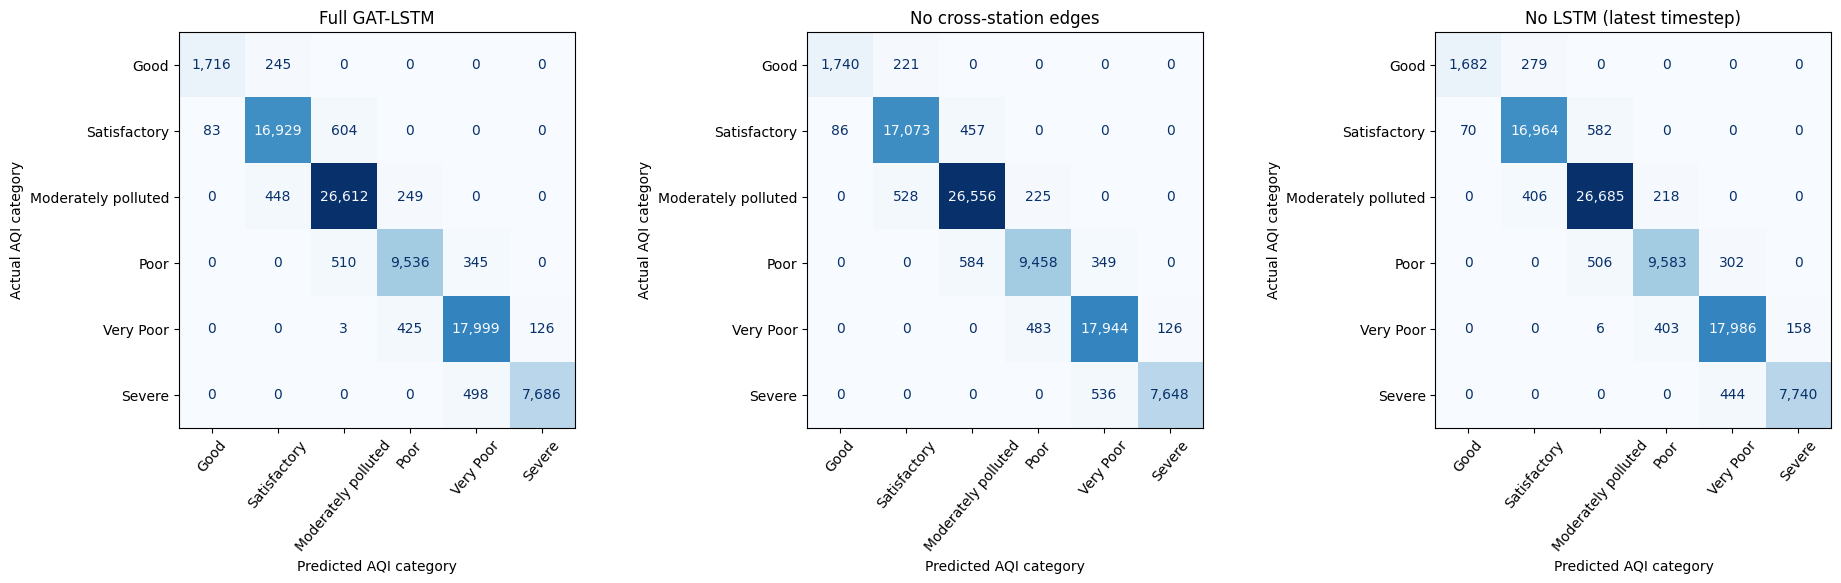

Saved: c:\Users\vabhi\Downloads\Implementation\Implementation\figures\exploratory\fig11_three_model_aqi_confusion_matrices.png


In [19]:
# ============================================================
# CELL 18 — Three-Model AQI Confusion Matrices
# ============================================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(19, 5.8))
for ax, model_name in zip(axes, model_order):
    cm = confusion_matrix(
        true_cls,
        aqi_prediction_classes[model_name],
        labels=AQI_CATS,
    )
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=AQI_CATS,
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format=",",
        xticks_rotation=50,
    )
    ax.set_title(model_name)
    ax.set_xlabel("Predicted AQI category")
    ax.set_ylabel("Actual AQI category")

fig.tight_layout()
fig_dir = ROOT / "figures/exploratory"
fig_dir.mkdir(parents=True, exist_ok=True)
fig_path = fig_dir / "fig11_three_model_aqi_confusion_matrices.png"
fig.savefig(fig_path, dpi=220, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

In [20]:
# ============================================================
# CELL 19 — Final Comparison Tables (Notebook Output)
# ============================================================

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

print("=" * 100)
print("FINAL POLLUTANT-WISE REGRESSION COMPARISON")
print("=" * 100)
print(
    regression_comparison_long[
        ["Pollutant", "Model", "MAE", "RMSE", "R2", "Valid test samples"]
    ].round(6).to_string(index=False)
)

print("\n" + "=" * 100)
print("FINAL CPCB-PERIOD AQI CLASSIFICATION COMPARISON")
print("=" * 100)
print(final_aqi_table.round(6).to_string(index=False))

print("\n" + "=" * 100)
print("ABLATION DELTAS RELATIVE TO FULL GAT-LSTM")
print("=" * 100)
delta_cols = [
    "Pollutant", "NoSpatial_MAE_change_%", "NoSpatial_R2_change",
    "NoLSTM_MAE_change_%", "NoLSTM_R2_change",
]
print(final_regression_table[delta_cols].round(6).to_string(index=False))

print("\nSaved result files:")
for path in [
    METRICS_DIR / "gat_lstm_three_model_regression_long.csv",
    METRICS_DIR / "gat_lstm_three_model_regression_wide.csv",
    METRICS_DIR / "gat_lstm_three_model_aqi_comparison.csv",
    METRICS_DIR / "gat_lstm_graph_ablation_test_metrics.csv",
    METRICS_DIR / "gat_lstm_temporal_ablation_test_metrics.csv",
    METRICS_DIR / "gat_lstm_temporal_ablation_training.csv",
    fig_path,
]:
    print(" -", path)

FINAL POLLUTANT-WISE REGRESSION COMPARISON
Pollutant                     Model       MAE      RMSE       R2  Valid test samples
       CO             Full GAT-LSTM  0.154622  0.340344 0.875074              188999
       CO    No cross-station edges  0.156790  0.342604 0.873409              188999
       CO No LSTM (latest timestep)  0.156323  0.339105 0.875981              188999
      NO2             Full GAT-LSTM  4.957168  9.168872 0.925033              190746
      NO2    No cross-station edges  5.035731  9.297083 0.922921              190746
      NO2 No LSTM (latest timestep)  5.088172  9.340070 0.922207              190746
       O3             Full GAT-LSTM  5.159182 10.976510 0.919588              189143
       O3    No cross-station edges  5.280289 11.145946 0.917086              189143
       O3 No LSTM (latest timestep)  5.396235 11.215438 0.916049              189143
     PM10             Full GAT-LSTM 22.283785 41.372500 0.920323              187845
     PM10    No cross-